In [1]:
%pip install matplotlib numpy scikit-learn opencv-python-headless kagglehub imutils

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, json, numpy as np, tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight
tfl = tf.keras.layers


2026-10-23 16:13:56.039739: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792772036.053753  181269 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792772036.058038  181269 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792772036.070679  181269 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792772036.070689  181269 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792772036.070691  181269 computation_placer.cc:177] computation placer alr

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("abd0id/mri-scans")

print("Path to dataset files:", path)

Path to dataset files: /root/.cache/kagglehub/datasets/abd0id/mri-scans/versions/1


In [4]:
import os

image_paths = []


In [5]:
directory = os.path.join(path, "processed")
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)
IMG_SIZE, BATCH_SIZE, SEED = (224, 224), 32, 42

class_names = sorted(d for d in os.listdir(directory) if os.path.isdir(f"{directory}/{d}"))
NUM_CLASSES = len(class_names)
paths, labels = [], []
for i, c in enumerate(class_names):
    for f in os.listdir(f"{directory}/{c}"):
        paths.append(f"{directory}/{c}/{f}"); labels.append(i)
paths, labels = np.array(paths), np.array(labels)

p_tr, p_tmp, y_tr, y_tmp = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_val, p_te, y_val, y_te = train_test_split(p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(len(p_tr), len(p_val), len(p_te), class_names)

def load(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)          # raw 0-255 preprocess_input is inside the model
    return img, tf.one_hot(label, NUM_CLASSES)

def make_ds(p, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if training:
        ds = ds.shuffle(len(p), seed=SEED)
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE)
    return ds.prefetch(tf.data.AUTOTUNE) if training else ds.cache().prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(p_tr, y_tr, True), make_ds(p_val, y_val), make_ds(p_te, y_te)
cw = dict(enumerate(compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_tr)))

4708 1009 1009 ['glioma', 'meningioma', 'notumor', 'pituitary']


I0000 00:00:1792772039.748362  181269 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22328 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3090, pci bus id: 0000:a2:00.0, compute capability: 8.6


In [6]:
data_augmentation = tf.keras.Sequential([
    tfl.RandomRotation(0.03), tfl.RandomZoom(0.1), tfl.RandomTranslation(0.05, 0.05)])  # training only
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

def build_model():
    base = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,),
                                             include_top=False, weights="imagenet")
    base.trainable = False
    inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
    x = data_augmentation(inputs)
    x = preprocess_input(x)
    x = base(x, training=False)            # keeps BatchNorm in inference mode also during finetuning
    x = tfl.GlobalAveragePooling2D()(x)
    x = tfl.Dropout(0.2)(x)
    outputs = tfl.Dense(NUM_CLASSES, activation="softmax")(x)
    return tf.keras.Model(inputs, outputs), base

model, base_model = build_model()
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

def callbacks(name):
    return [
        tf.keras.callbacks.ModelCheckpoint(f"{OUT}/{name}_best.keras", monitor="val_loss", save_best_only=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        tf.keras.callbacks.BackupAndRestore(f"{OUT}/backup_{name}"),
    ]

h1 = model.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=cw, callbacks=callbacks("transfer"))

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/15


I0000 00:00:1792772048.246061  182061 cuda_dnn.cc:529] Loaded cuDNN version 90300


148/148 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.6044 - loss: 0.9485 - val_accuracy: 0.7988 - val_loss: 0.5450
Epoch 2/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.8398 - loss: 0.4396 - val_accuracy: 0.7820 - val_loss: 0.5542
Epoch 3/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.8602 - loss: 0.3767 - val_accuracy: 0.7671 - val_loss: 0.6185
Epoch 4/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.8775 - loss: 0.3392 - val_accuracy: 0.8375 - val_loss: 0.4107
Epoch 5/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.8905 - loss: 0.3022 - val_accuracy: 0.8404 - val_loss: 0.3859
Epoch 6/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.8977 - loss: 0.2811 - val_accuracy: 0.8355 - val_loss: 0.4088
Epoch 7/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.8965 - loss: 0.2692 - val_accuracy: 0.8236 - val_loss: 0.4727
Epoch 8/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.8937 - loss: 0.2769 - val_accuracy: 0.81

In [7]:
FINE_TUNE_AT = 100                          # MobileNetV2 has 154 layers: freeze 0-99, train 100+
base_model.trainable = True
for layer in base_model.layers[:FINE_TUNE_AT]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),   # 10x lower: gentle updates, keeps ImageNet knowledge
              loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

h2 = model.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=cw, cal━━━━━━━━━━━━6s 43ms/step - accuracy: 0.9833 - loss: 0.0523 - val_accuracy: 0.9078 - val_loss: 0.3752
Epoch 5/15
148/148 ━━━━━━━━━━━━━━━━━7s 49ms/step - accuracy: 0.9808 - loss: 0.0534 - val_accuracy: 0.9296 - val_loss: 0.2417
Epoch 6/15
lbacks=callbacks("finetune"))━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.9720 - loss: 0.0781 - val_accuracy: 0.8940 - val_loss: 0.3848
Epoch 4/15
148/148 ━━━━━━━━━━━━━━━━━6s 43ms/step - accuracy: 0.9833 - loss: 0.0523 - val_accuracy: 0.9078 - val_loss: 0.3752
Epoch 5/15
148/148 ━━━━━━━━━━━━━━━━━7s 49ms/step - accuracy: 0.9808 - loss: 0.0534 - val_accuracy: 0.9296 - val_loss: 0.2417
Epoch 6/15
148/148 ━━━━━━━━━━━━━━━━━8s 53ms/step - accuracy: 0.9872 - loss: 0.0387 - val_accuracy: 0.9485 - val_loss: 0.1617
Epoch 7/15
━━━━6s 43ms/step - accuracy: 0.9833 - loss: 0.0523 - val_accuracy: 0.9078 - val_loss: 0.3752
Epoch 5/15
148/148 ━━━━━━━━━━━━━━━━━7s 49ms/step - accuracy: 0.9808 - loss: 0.0534 - val_accuracy: 0.9296 - val_loss: 0.2417
Epoch 6/15
148/148 ━━━━━━━━━━━━━━━━━8s 53ms/step - accuracy: 0.9872 - loss: 0.0387 - val_accuracy: 0.9485 - val_loss: 0.1617
Epoch 7/15
148/148 ━━━━━━━━━━━━━━━━━7s 43ms/step - accuracy: 0.9947 - loss: 0.0208 - val_accuracy: 0.9167 - val_loss: 0.2647
Epoch 8/15


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 1,866,564 (7.12 MB)

 Non-trainable params: 396,544 (1.51 MB)

Epoch 1/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 18s 56ms/step - accuracy: 0.8430 - loss: 0.4700 - val_accuracy: 0.7919 - val_loss: 0.6597
Epoch 2/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.9444 - loss: 0.1474 - val_accuracy: 0.8920 - val_loss: 0.3358
Epoch 3/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.9720 - loss: 0.0781 - val_accuracy: 0.8940 - val_loss: 0.3848
Epoch 4/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step - accuracy: 0.9833 - loss: 0.0523 - val_accuracy: 0.9078 - val_loss: 0.3752
Epoch 5/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 49ms/step - accuracy: 0.9808 - loss: 0.0534 - val_accuracy: 0.9296 - val_loss: 0.2417
Epoch 6/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 8s 53ms/step - accuracy: 0.9872 - loss: 0.0387 - val_accuracy: 0.9485 - val_loss: 0.1617
Epoch 7/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 43ms/step - accuracy: 0.9947 - loss: 0.0208 - val_accuracy: 0.9167 - val_loss: 0.2647
Epoch 8/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - accuracy: 0.9871 - loss: 0.0363 - val_acc

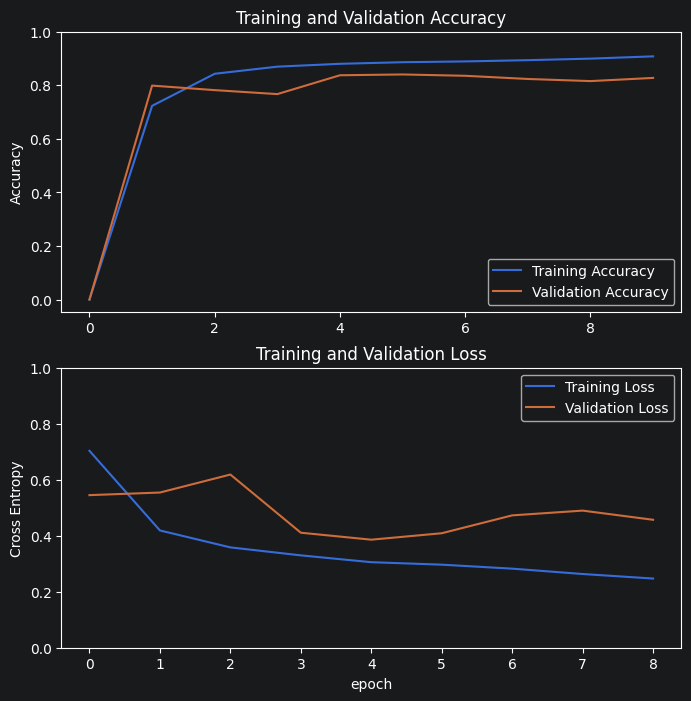

In [8]:
import matplotlib.pyplot as plt

# Changed 'history.history' to 'h1.history' to match your training variable
acc = [0.] + h1.history['accuracy']
val_acc = [0.] + h1.history['val_accuracy']

loss = h1.history['loss']
val_loss = h1.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()